<a href="https://colab.research.google.com/github/habibiputrar/DeepLearning_B_2411531001_Habibi-Putra-Rizqullah/blob/main/Praktikum5/2411531001_Habibi_Putra_Rizqullah_Program5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Deep Learning Minggu 5
## Gated Recurrent Unit untuk Prediksi Data Sekuensial

**Nama:** Habibi Putra Rizqullah  
**NIM:** 2411531001  
**Kelas:** Deep Learning B

# BAGIAN I PRAKTIKUM

Bagian ini menggunakan kode implementasi dari Modul Praktikum Deep Learning Minggu 5. Kode hanya dipisahkan menjadi beberapa sel sesuai langkahnya. Nama variabel, dataset, model, pengaturan training, dan cara prediksi dipertahankan seperti pada modul.

## 1. Persiapan Library

Mengimpor PyTorch, NumPy, dan Matplotlib sesuai modul. Pastikan ketiganya sudah terpasang sebelum menjalankan notebook.

In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

## 2. Membuat Dataset dan Sequence

Data sinus dibuat dari 1.000 titik. Setiap 20 nilai digunakan untuk memprediksi satu nilai berikutnya. Sesuai kode modul, seluruh sequence digunakan untuk training tanpa pembagian training dan testing.

In [2]:
# 1. Membuat dataset sinusoidal
data = np.sin(np.linspace(0, 100, 1000))
seq_length = 20

def create_sequences(data, seq_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        xs.append(data[i:i+seq_length])
        ys.append(data[i+seq_length])
    return np.array(xs), np.array(ys)

X, y = create_sequences(data, seq_length)
X = torch.FloatTensor(X).unsqueeze(-1)
y = torch.FloatTensor(y).unsqueeze(-1)

## 3. Membuat Model GRU

Model menggunakan `nn.GRU` dan lapisan linear. Keluaran langkah waktu terakhir digunakan untuk menghasilkan satu nilai prediksi.

In [3]:
# 2. Definisi model GRU
class GRUModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, output_size=1, num_layers=1):
        super(GRUModel, self).__init__()
        self.gru = nn.GRU(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, _ = self.gru(x)
        out = self.fc(out[:, -1, :])
        return out

## 4. Inisialisasi Model Loss dan Optimizer

Model memakai hidden size 64 dan satu layer. Fungsi loss adalah MSE, sedangkan optimizer adalah Adam dengan learning rate 0,01.

In [4]:
# 3. Inisialisasi model, loss, optimizer
model = GRUModel()
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

## 5. Melatih Model

Training dijalankan selama 50 epoch. Loss setiap epoch disimpan dan ditampilkan setiap 10 epoch.

In [5]:
# 4. Training loop
epochs = 50
losses = []
for epoch in range(epochs):
    optimizer.zero_grad()
    outputs = model(X)
    loss = criterion(outputs, y)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if (epoch+1) % 10 == 0:
        print(f'Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}')

Epoch [10/50], Loss: 0.0326
Epoch [20/50], Loss: 0.0092
Epoch [30/50], Loss: 0.0016
Epoch [40/50], Loss: 0.0003
Epoch [50/50], Loss: 0.0003


## 6. Menampilkan Grafik Loss

Grafik menunjukkan perubahan loss selama proses training.

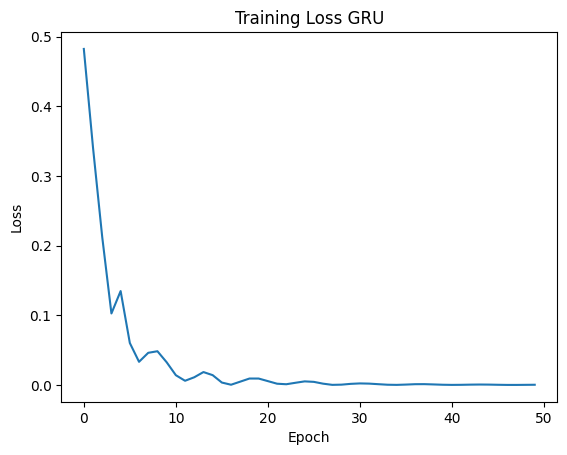

In [6]:
# 5. Plot loss
plt.plot(losses)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss GRU')
plt.show()

## 7. Menampilkan Hasil Prediksi

Prediksi dihitung pada sequence yang juga digunakan saat training, sesuai modul. Grafik ini menggambarkan kecocokan terhadap data training dan belum mengukur generalisasi pada data baru.

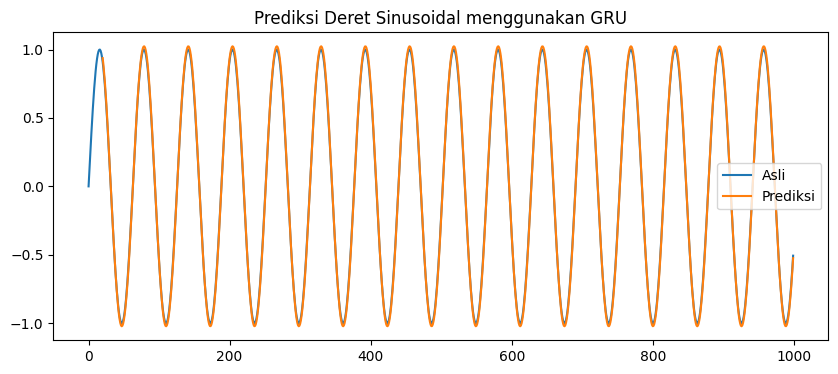

In [7]:
# 6. Prediksi
with torch.no_grad():
    preds = model(X).numpy()

plt.figure(figsize=(10,4))
plt.plot(data, label='Asli')
plt.plot(np.arange(seq_length, len(preds)+seq_length), preds, label='Prediksi')
plt.legend()
plt.title('Prediksi Deret Sinusoidal menggunakan GRU')
plt.show()

## 8. Analisis Hasil Praktikum

Analisis dilakukan dengan melihat penurunan loss selama training dan kesesuaian hasil prediksi dengan data asli. GRU kemudian dibandingkan dengan LSTM dari Praktikum 4 menggunakan data sinus dan pengaturan training yang sama. Waktu training kedua model juga dicatat untuk membandingkan efisiensinya.

Seluruh data digunakan untuk training, sehingga nilai MSE yang diperoleh menunjukkan kesalahan prediksi pada data yang telah dipelajari model. Perbandingan kecepatan GRU dan LSTM didasarkan pada waktu training yang diperoleh dalam percobaan ini.

In [8]:
import time
import pandas as pd

class LSTMModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, output_size=1, num_layers=1):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
        )
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])

# Fungsi tambahan untuk mencatat waktu dan membandingkan arsitektur.
# Model, loss, optimizer, dan training mengikuti pola kode modul.
def jalankan_eksperimen(kelas_model, X_data, y_data, hidden_size=64, num_layers=1):
    torch.manual_seed(42)
    model_eksperimen = kelas_model(hidden_size=hidden_size, num_layers=num_layers)
    criterion_eksperimen = nn.MSELoss()
    optimizer_eksperimen = torch.optim.Adam(model_eksperimen.parameters(), lr=0.01)
    losses_eksperimen = []
    mulai = time.perf_counter()
    for epoch in range(50):
        optimizer_eksperimen.zero_grad()
        outputs = model_eksperimen(X_data)
        loss = criterion_eksperimen(outputs, y_data)
        loss.backward()
        optimizer_eksperimen.step()
        losses_eksperimen.append(loss.item())
    waktu = time.perf_counter() - mulai
    with torch.no_grad():
        prediksi = model_eksperimen(X_data).numpy()
    return model_eksperimen, losses_eksperimen, prediksi, waktu

hasil_sinus = []
for nama, kelas in [("GRU", GRUModel), ("LSTM", LSTMModel)]:
    model_s, loss_s, pred_s, waktu_s = jalankan_eksperimen(kelas, X, y)
    hasil_sinus.append({"Model": nama, "Hidden Size": 64, "Num Layers": 1,
                        "Loss Akhir": loss_s[-1], "Waktu Training (s)": waktu_s})
display(pd.DataFrame(hasil_sinus))

,Model,Hidden Size,Num Layers,Loss Akhir,Waktu Training (s)
0,GRU,64,1,0.000070,3.692325
1,LSTM,64,1,0.000403,7.330393


# BAGIAN II TUGAS INDIVIDU

Pada bagian ini, model dilatih menggunakan data cosinus dengan tiga kombinasi hidden size dan jumlah layer. Loss akhir dan waktu training setiap konfigurasi GRU kemudian dibandingkan dengan model LSTM dari Praktikum 4.

## 1. Mengganti Dataset Menjadi Cosinus

Perubahan fungsi pembangkit data adalah dari `np.sin` menjadi `np.cos`. Jumlah titik, rentang, panjang sequence, dan pembentukan tensor tetap mengikuti kode modul. Seluruh data tetap digunakan untuk training.

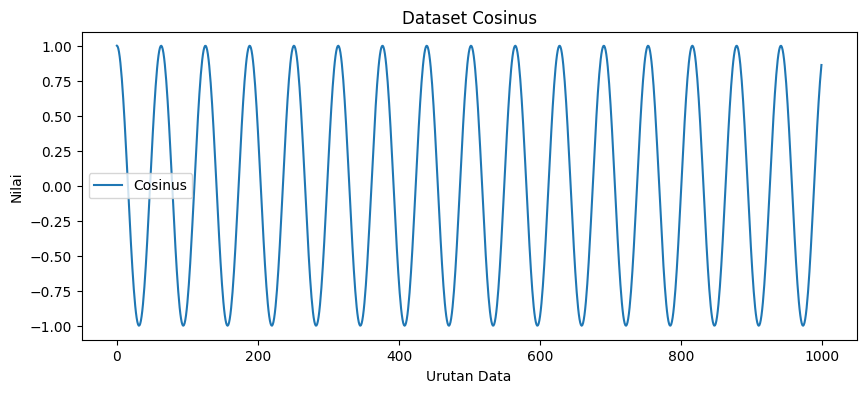

In [9]:
data_cosinus = np.cos(np.linspace(0, 100, 1000))
X_cos, y_cos = create_sequences(data_cosinus, seq_length)
X_cos = torch.FloatTensor(X_cos).unsqueeze(-1)
y_cos = torch.FloatTensor(y_cos).unsqueeze(-1)

plt.figure(figsize=(10, 4))
plt.plot(data_cosinus, label='Cosinus')
plt.xlabel('Urutan Data')
plt.ylabel('Nilai')
plt.title('Dataset Cosinus')
plt.legend()
plt.show()

## 2. Menjalankan Eksperimen GRU dan LSTM

Konfigurasi yang digunakan adalah hidden size 32 dengan satu layer, hidden size 64 dengan satu layer, serta hidden size 64 dengan dua layer. Masing-masing menggunakan 50 epoch, Adam, learning rate 0,01, dan MSE seperti modul.

Seed tambahan digunakan sebelum setiap eksperimen agar hasil lebih mudah direproduksi dalam lingkungan yang sama. Loss akhir adalah loss epoch terakhir sebelum pembaruan bobot terakhir, mengikuti `losses[-1]` pada loop modul. Waktu hanya mencakup loop training, tanpa pembuatan model, prediksi, dan plotting.

In [10]:
konfigurasi = [(32, 1), (64, 1), (64, 2)]
hasil_tugas = []
detail_tugas = {}
for nomor, (hidden_size, num_layers) in enumerate(konfigurasi, start=1):
    for arsitektur, kelas in [("GRU", GRUModel), ("LSTM", LSTMModel)]:
        nama = f"{arsitektur}_{nomor}"
        print(f"Training {nama}: hidden={hidden_size}, layers={num_layers}")
        model_t, losses_t, prediksi_t, waktu_t = jalankan_eksperimen(
            kelas, X_cos, y_cos, hidden_size, num_layers
        )
        hasil_tugas.append({
            "Model": nama, "Arsitektur": arsitektur,
            "Hidden Size": hidden_size, "Num Layers": num_layers,
            "Loss Akhir": losses_t[-1], "Waktu Training (s)": waktu_t,
            "Catatan": f"{num_layers} layer, hidden size {hidden_size}"
        })
        detail_tugas[nama] = {"losses": losses_t, "predictions": prediksi_t}

tabel_hasil = pd.DataFrame(hasil_tugas)
kolom_modul = ["Model", "Hidden Size", "Num Layers", "Loss Akhir", "Waktu Training (s)", "Catatan"]
print("Tabel eksperimen GRU sesuai kolom modul")
display(tabel_hasil.loc[tabel_hasil["Arsitektur"] == "GRU", kolom_modul])
print("Tabel perbandingan dengan LSTM")
display(tabel_hasil[kolom_modul])

Training GRU_1: hidden=32, layers=1
Training LSTM_1: hidden=32, layers=1
Training GRU_2: hidden=64, layers=1
Training LSTM_2: hidden=64, layers=1
Training GRU_3: hidden=64, layers=2
Training LSTM_3: hidden=64, layers=2
Tabel eksperimen GRU sesuai kolom modul


,Model,Hidden Size,Num Layers,Loss Akhir,Waktu Training (s),Catatan
0,GRU_1,32,1,0.000118,1.730997,"1 layer, hidden size 32"
2,GRU_2,64,1,0.000097,3.931472,"1 layer, hidden size 64"
4,GRU_3,64,2,0.000751,11.717173,"2 layer, hidden size 64"


Tabel perbandingan dengan LSTM


,Model,Hidden Size,Num Layers,Loss Akhir,Waktu Training (s),Catatan
0,GRU_1,32,1,0.000118,1.730997,"1 layer, hidden size 32"
1,LSTM_1,32,1,0.000505,2.947198,"1 layer, hidden size 32"
2,GRU_2,64,1,0.000097,3.931472,"1 layer, hidden size 64"
3,LSTM_2,64,1,0.000325,7.953191,"1 layer, hidden size 64"
4,GRU_3,64,2,0.000751,11.717173,"2 layer, hidden size 64"
5,LSTM_3,64,2,0.001233,14.798735,"2 layer, hidden size 64"


## 3. Menampilkan Grafik Loss dan Prediksi

Setiap pasangan GRU dan LSTM dibandingkan pada konfigurasi yang sama. Prediksi ditampilkan terhadap seluruh data cosinus sebagaimana pola plotting pada modul. Semua hasil berasal dari training yang dijalankan di notebook ini.

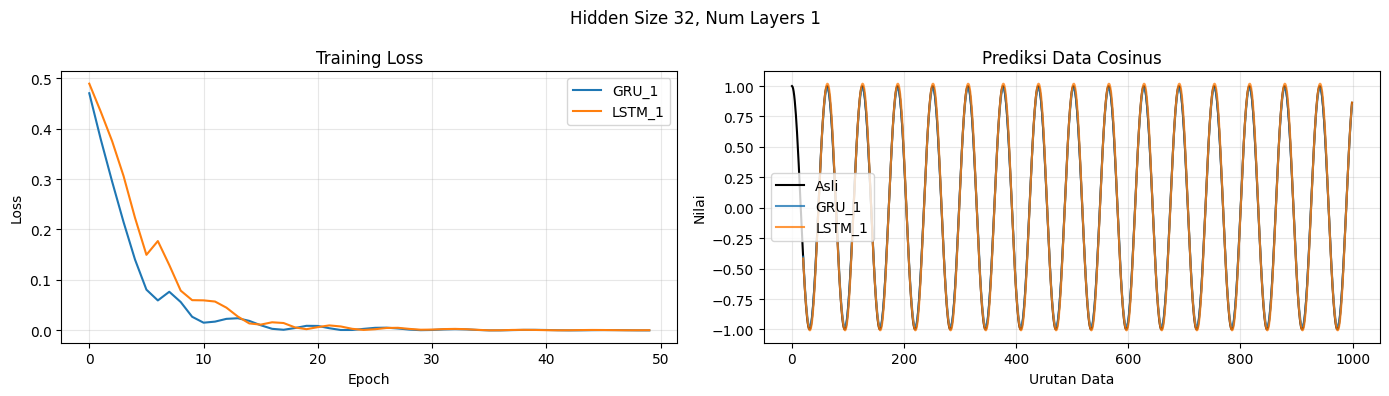

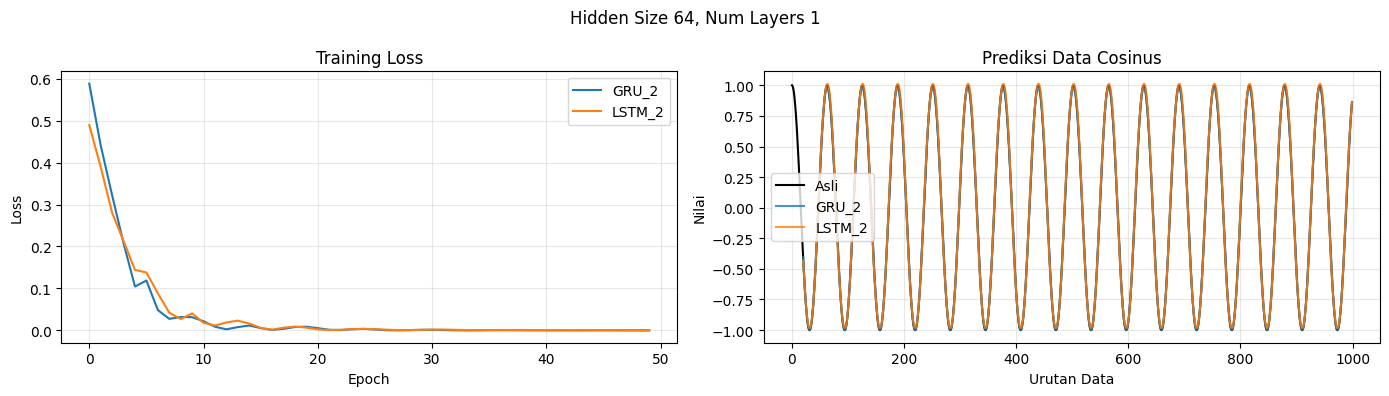

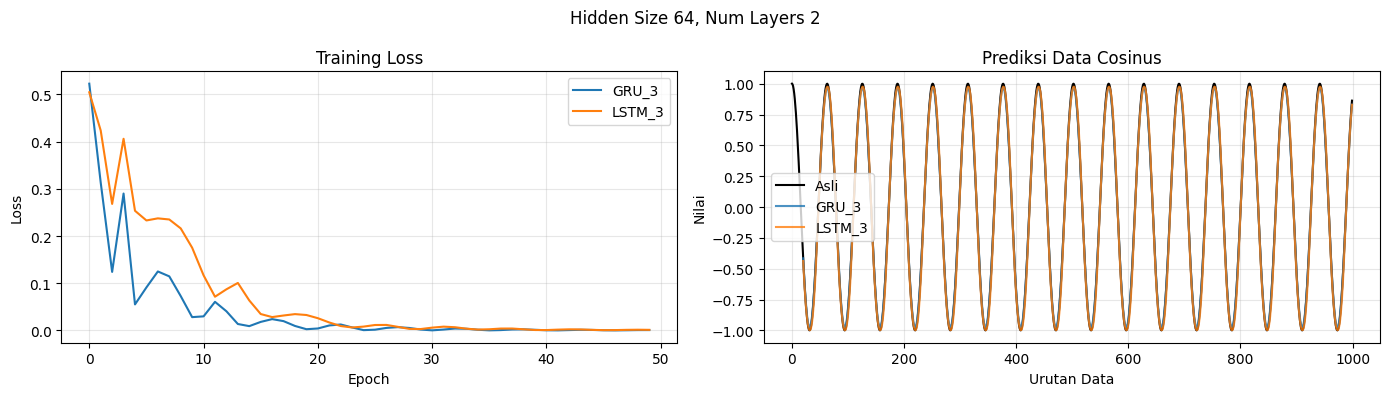

In [11]:
for nomor, (hidden_size, num_layers) in enumerate(konfigurasi, start=1):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[1].plot(data_cosinus, label="Asli", color="black")
    for arsitektur in ["GRU", "LSTM"]:
        nama = f"{arsitektur}_{nomor}"
        info = detail_tugas[nama]
        axes[0].plot(info["losses"], label=nama)
        axes[1].plot(
            np.arange(seq_length, len(info["predictions"]) + seq_length),
            info["predictions"].ravel(), label=nama, alpha=0.8
        )
    axes[0].set(title="Training Loss", xlabel="Epoch", ylabel="Loss")
    axes[1].set(title="Prediksi Data Cosinus", xlabel="Urutan Data", ylabel="Nilai")
    for ax in axes:
        ax.legend()
        ax.grid(alpha=0.3)
    fig.suptitle(f"Hidden Size {hidden_size}, Num Layers {num_layers}")
    plt.tight_layout()
    plt.show()

## 4. Analisis dan Kesimpulan Efisiensi GRU

Sel berikut membandingkan loss akhir dan waktu training berdasarkan hasil aktual. Loss lebih kecil menunjukkan kecocokan yang lebih baik pada data training yang sama. Pengukuran satu kali dapat dipengaruhi kondisi komputer; kesimpulannya terbatas pada percobaan ini.

Amati kestabilan loss dari kurva, bukan hanya titik terakhir. GRU memiliki parameter lebih sedikit pada konfigurasi setara, tetapi klaim lebih cepat perlu didukung waktu yang diperoleh. Overfitting belum dapat dipastikan dari kode modul karena tidak ada data validasi terpisah. Jika diperlukan pada pengembangan lanjutan, gunakan validasi kronologis dan regularisasi; dropout recurrent bawaan hanya bekerja di antara lapisan dan memerlukan lebih dari satu layer.

In [12]:
for nomor, (hidden_size, num_layers) in enumerate(konfigurasi, start=1):
    gru = tabel_hasil[tabel_hasil["Model"] == f"GRU_{nomor}"].iloc[0]
    lstm = tabel_hasil[tabel_hasil["Model"] == f"LSTM_{nomor}"].iloc[0]
    print(f"\nKonfigurasi hidden={hidden_size}, layers={num_layers}")
    for row in [gru, lstm]:
        print(f"{row['Model']} | Loss akhir: {row['Loss Akhir']:.6f} | "
              f"Waktu training: {row['Waktu Training (s)']:.3f} detik")
    for kolom, label in [("Loss Akhir", "loss akhir lebih rendah"),
                        ("Waktu Training (s)", "waktu training lebih singkat")]:
        if gru[kolom] == lstm[kolom]:
            print(f"Kedua model memiliki {kolom.lower()} yang sama.")
        else:
            nama = "GRU" if gru[kolom] < lstm[kolom] else "LSTM"
            print(f"Pada percobaan ini, {nama} memiliki {label}.")
print("\nHasil pada data periodik sederhana ini tidak membuktikan keunggulan universal salah satu model.")


Konfigurasi hidden=32, layers=1
GRU_1 | Loss akhir: 0.000118 | Waktu training: 1.731 detik
LSTM_1 | Loss akhir: 0.000505 | Waktu training: 2.947 detik
Pada percobaan ini, GRU memiliki loss akhir lebih rendah.
Pada percobaan ini, GRU memiliki waktu training lebih singkat.

Konfigurasi hidden=64, layers=1
GRU_2 | Loss akhir: 0.000097 | Waktu training: 3.931 detik
LSTM_2 | Loss akhir: 0.000325 | Waktu training: 7.953 detik
Pada percobaan ini, GRU memiliki loss akhir lebih rendah.
Pada percobaan ini, GRU memiliki waktu training lebih singkat.

Konfigurasi hidden=64, layers=2
GRU_3 | Loss akhir: 0.000751 | Waktu training: 11.717 detik
LSTM_3 | Loss akhir: 0.001233 | Waktu training: 14.799 detik
Pada percobaan ini, GRU memiliki loss akhir lebih rendah.
Pada percobaan ini, GRU memiliki waktu training lebih singkat.

Hasil pada data periodik sederhana ini tidak membuktikan keunggulan universal salah satu model.


## 5. Jawaban Pertanyaan Reflektif

### 1. Mengapa GRU lebih cepat daripada LSTM?

GRU memiliki dua gerbang utama dan tidak menggunakan cell state terpisah seperti LSTM. Pada input size, hidden size, dan jumlah layer yang sama, GRU memiliki lebih sedikit parameter sehingga kebutuhan komputasinya umumnya lebih rendah. Akan tetapi, waktu aktual bergantung pada perangkat dan implementasi backend, sehingga GRU tidak selalu lebih cepat pada setiap percobaan.

### 2. Apa peran update gate dalam GRU?

Update gate mengatur keseimbangan antara informasi hidden state sebelumnya yang dipertahankan dan informasi kandidat baru yang digunakan. Mekanisme ini membantu model mempertahankan informasi penting selama memproses sekuens.

### 3. Apakah GRU cocok untuk data teks yang sangat panjang? Jelaskan alasanmu.

GRU dapat digunakan untuk data teks dan membantu menangani ketergantungan sekuens dibandingkan RNN biasa. Namun, teks yang sangat panjang tetap menantang karena informasi harus diringkas dalam hidden state dengan kapasitas terbatas. Model berbasis attention dapat dipertimbangkan untuk hubungan antarkata yang sangat berjauhan. Pemilihan model perlu mempertimbangkan panjang teks, tugas, dan sumber daya komputasi.